[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_vr_profile/BA_L2_vr_profile.ipynb)

# BA_L2_vr_profile: The Variance-Ratio Profile

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Variance ratios VR(q) for horizons of 2 to 30 days for Bitcoin, Ethereum and the S&P 500, daily log returns 1 January 2018 to 18 September 2026, with the heteroskedasticity-robust 95% band of the random walk for Bitcoin.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

The **variance ratio** compares the variance of $q$-day returns with $q$ times the daily variance:

$$\mathrm{VR}(q) = \frac{\mathrm{Var}(r_t + r_{t-1} + \dots + r_{t-q+1})}{q\,\mathrm{Var}(r_t)}.$$

Under a random walk $\mathrm{VR}(q) = 1$; $\mathrm{VR} > 1$ indicates trends (momentum), $\mathrm{VR} < 1$ reversals
(mean reversion). The test statistic robust to volatility clustering (Lo and MacKinlay, 1988) is

$$Z^*(q) = \frac{\widehat{\mathrm{VR}}(q) - 1}{\sqrt{\hat\theta^*(q)/n}}, \qquad
\hat\theta^*(q) = \sum_{j=1}^{q-1}\Big[\frac{2(q-j)}{q}\Big]^2 \frac{n\sum_{t}(r_t - \bar r)^2(r_{t-j} - \bar r)^2}{\Big[\sum_{t}(r_t - \bar r)^2\Big]^2},$$

approximately standard Normal; $|Z^*| > 1.96$ rejects the random walk at 5%. The $q$-day sums overlap (one on every
day). Data: daily log returns in percent, 1 January 2018 to 18 September 2026, every close in the EODHD files.

**How to read the chart.** Each line is $\widehat{\mathrm{VR}}(q)$ against the horizon $q$; the shaded band is
$1 \pm 1.96\sqrt{\hat\theta^*(q)/n}$ for Bitcoin. Points inside the band do not reject the random walk.

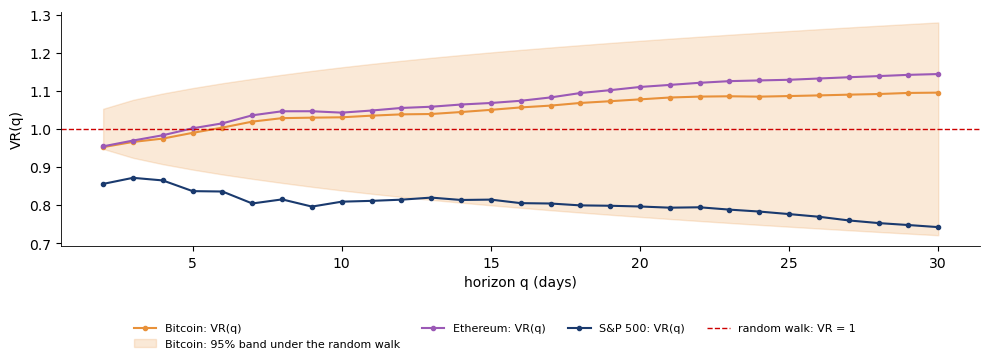

In [5]:
def vr_stats(r, q):
    # variance ratio VR(q) from overlapping q-day sums and the robust standard error sqrt(theta*(q)/n)
    r = r.values; n = len(r); mu = r.mean(); e = r - mu
    s1 = (e ** 2).sum() / n
    rq = pd.Series(r).rolling(q).sum().dropna().values
    vr = ((rq - q * mu) ** 2).sum() / (n * q) / s1
    den = ((e ** 2).sum()) ** 2
    theta = sum((2 * (q - j) / q) ** 2 * (e[j:] ** 2 * e[:-j] ** 2).sum() / den * n for j in range(1, q))
    return vr, np.sqrt(theta / n)


R = {'Bitcoin': rets(prices('BTC-USD.CC')), 'Ethereum': rets(prices('ETH-USD.CC')), 'S&P 500': rets(prices('GSPC.INDX'))}
qs = np.arange(2, 31)
out = {k: np.array([vr_stats(R[k], q) for q in qs]) for k in R}

fig, ax = plt.subplots(figsize=(10, 3.6))
for k, col in [('Bitcoin', BTC), ('Ethereum', ETH), ('S&P 500', BLUE)]:
    ax.plot(qs, out[k][:, 0], color=col, marker='o', ms=3, label=f'{k}: VR(q)')
    if k == 'Bitcoin':
        ax.fill_between(qs, 1 - 1.96 * out[k][:, 1], 1 + 1.96 * out[k][:, 1], color=BTC, alpha=0.2,
                        label='Bitcoin: 95% band under the random walk')
ax.axhline(1, color=RED, ls='--', lw=1, label='random walk: VR = 1')
ax.set_xlabel('horizon q (days)'); ax.set_ylabel('VR(q)')
slide_legend(fig, 0.14, ncol=4)
save_fig(fig, 'ba_l2_vr_profile')

In [6]:
tab = pd.DataFrame({k: {'n': len(R[k]), 'VR(5)': o[3, 0], 'Z*(5)': (o[3, 0] - 1) / o[3, 1],
                        'VR(20)': o[18, 0], 'Z*(20)': (o[18, 0] - 1) / o[18, 1]} for k, o in out.items()}).T
tab['n'] = tab['n'].astype(int)
print(tab.round(3).to_string())

             n  VR(5)  Z*(5)  VR(20)  Z*(20)
Bitcoin   3183  0.989 -0.193   1.077   0.656
Ethereum  3183  1.001  0.026   1.110   0.947
S&P 500   2190  0.836 -1.207   0.796  -0.756
